# Merge Sort and Quicksort

## Merge Sort

Merge sort is a divide-and-conquer algorithm:

- **Divide** the array into two halves.
- **Conquer** by recursively sorting each half.
- **Combine** the two sorted halves using a `merge` step that runs in $O(n)$ time.

Overall running time: $O(n \log n)$ in all cases.

In [1]:
def merge(left, right):
    """Merge two sorted lists into a single sorted list."""
    result = []
    i = j = 0
    while i < len(left) and j < len(right):
        if left[i] <= right[j]:
            result.append(left[i])
            i += 1
        else:
            result.append(right[j])
            j += 1
    # Append any remaining elements
    result.extend(left[i:])
    result.extend(right[j:])
    return result


def merge_sort(arr):
    """Sort a list using merge sort. Returns a new sorted list."""
    if len(arr) <= 1:
        return arr[:]

    mid = len(arr) // 2
    left = merge_sort(arr[:mid])
    right = merge_sort(arr[mid:])

    return merge(left, right)


In [2]:
# Quick test
test_array = [38, 27, 43, 3, 9, 82, 10]
print("Original:", test_array)
print("Sorted:  ", merge_sort(test_array))


Original: [38, 27, 43, 3, 9, 82, 10]
Sorted:   [3, 9, 10, 27, 38, 43, 82]


## Randomized Quicksort

Quicksort is also divide-and-conquer, but it does the work *before* the recursive calls (via partitioning) instead of after (via merging):

- **Pick a pivot.**
- **Partition** the array so elements smaller than the pivot come before it and elements larger come after.
- **Recurse** on the two partitions.

In this implementation, `partition(A, p, q)` uses `A[p]` (the first element of the range) as the pivot `x`. `randomized_partition` picks a uniformly random element and swaps it into position `p` first, then calls the same `partition` — this is what makes the pivot choice random and avoids the $O(n^2)$ worst case that a fixed first-element pivot hits on already-sorted or adversarial input.

This implementation sorts **in place**.

In [3]:
import random

def partition(arr, p, q):
    """Partition arr[p..q] using arr[p] as the pivot.
    Rearranges arr[p..q] in place and returns the pivot's final index i,
    such that arr[p..i-1] <= arr[i] and arr[i+1..q] > arr[i]."""
    x = arr[p]      # pivot
    i = p
    for j in range(p + 1, q + 1):
        if arr[j] <= x:
            i = i + 1
            arr[i], arr[j] = arr[j], arr[i]
    arr[p], arr[i] = arr[i], arr[p]
    return i


def randomized_partition(arr, p, q):
    """Choose a random pivot, swap it into position p, then partition normally."""
    rand_index = random.randint(p, q)
    arr[rand_index], arr[p] = arr[p], arr[rand_index]
    return partition(arr, p, q)


def quicksort(arr, p=0, q=None):
    """Sort arr[p..q] in place using randomized quicksort."""
    if q is None:
        q = len(arr) - 1

    if p < q:
        pivot_index = randomized_partition(arr, p, q)
        quicksort(arr, p, pivot_index - 1)
        quicksort(arr, pivot_index + 1, q)

    return arr


In [4]:
# Quick test
test_array = [38, 27, 43, 3, 9, 82, 10]
print("Original:", test_array)
quicksort(test_array)
print("Sorted:  ", test_array)


Original: [38, 27, 43, 3, 9, 82, 10]
Sorted:   [3, 9, 10, 27, 38, 43, 82]


**Note:** unlike `merge_sort` above (which returns a *new* list), `quicksort` sorts *in place* and also returns the array for convenience. Keep this difference in mind — you may need to pass in a **copy** of a list (`arr[:]` or `list(arr)`) if you want to keep the original around.

## Exercises

1. Plot graphs to illustrate that Randomized Quicksort is generally faster than Mergesort, Bubblesort. Justify why this happens.
2. Give inputs in such a way that mergesort is faster than randomized quicksort. Plot the corresponding graph. Justify why this happens.
3. Modify all three algorithms to count the number of comparisons and swaps. Plot the number of comparisons and swaps against input size and compare the results.
4. When will you use the following algorithms?

    (i) Bubblesort alone
   
   (ii) Mergesort alone
   
   (iii) Randomized quicksort alone
   
   (iv) Mergesort first, followed by quicksort
   
   (v) Quicksort first, followed by mergesort


## Solution 1
Randomized Quicksort: expected time is O(nlogn), and it sorts in place, so it has good cache behavior and relatively little extra memory usage

Mergesort: always takes O(nlogn) but the Python implementation creates many temporary lists during slicing and merging

Bubblesort: takes O(n2) average time so its running time grows very quickly as n increases

n=100: Merge=0.000108s, Quick=0.000081s, Bubble=0.000312s
n=200: Merge=0.000237s, Quick=0.000175s, Bubble=0.001248s
n=400: Merge=0.000532s, Quick=0.000437s, Bubble=0.005143s
n=800: Merge=0.001024s, Quick=0.000806s, Bubble=0.021223s
n=1200: Merge=0.001615s, Quick=0.001251s, Bubble=0.049431s
n=1600: Merge=0.002437s, Quick=0.001773s, Bubble=0.088772s
n=2000: Merge=0.002788s, Quick=0.002342s, Bubble=0.141873s
n=4000: Merge=0.006483s, Quick=0.004712s, Bubble=0.901297s
n=8000: Merge=0.024284s, Quick=0.017046s, Bubble=4.194284s
n=16000: Merge=0.053076s, Quick=0.036297s, Bubble=16.827933s
n=25000: Merge=0.086797s, Quick=0.061017s, Bubble=41.191312s


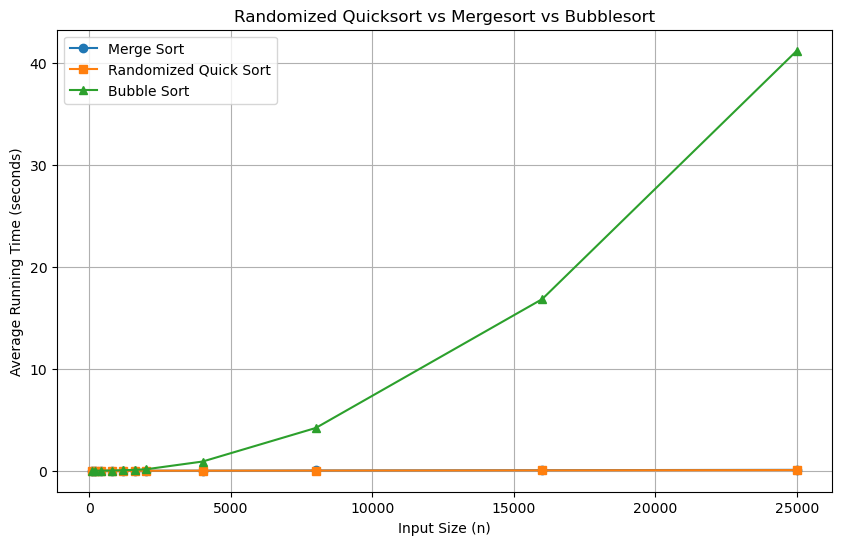

In [5]:
import random
import time
import matplotlib.pyplot as plt


# ============================================================
# MERGE SORT
# ============================================================

def merge(left, right):
    result = []
    i = j = 0

    while i < len(left) and j < len(right):
        if left[i] <= right[j]:
            result.append(left[i])
            i += 1
        else:
            result.append(right[j])
            j += 1

    result.extend(left[i:])
    result.extend(right[j:])

    return result


def merge_sort(arr):
    if len(arr) <= 1:
        return arr[:]

    mid = len(arr) // 2

    left = merge_sort(arr[:mid])
    right = merge_sort(arr[mid:])

    return merge(left, right)


# ============================================================
# RANDOMIZED QUICKSORT
# ============================================================

def partition(arr, p, q):
    x = arr[p]
    i = p

    for j in range(p + 1, q + 1):
        if arr[j] <= x:
            i += 1
            arr[i], arr[j] = arr[j], arr[i]

    arr[p], arr[i] = arr[i], arr[p]

    return i


def randomized_partition(arr, p, q):
    rand_index = random.randint(p, q)

    arr[rand_index], arr[p] = arr[p], arr[rand_index]

    return partition(arr, p, q)


def quicksort(arr, p=0, q=None):
    if q is None:
        q = len(arr) - 1

    if p < q:
        pivot_index = randomized_partition(arr, p, q)

        quicksort(arr, p, pivot_index - 1)
        quicksort(arr, pivot_index + 1, q)

    return arr


# ============================================================
# BUBBLE SORT
# ============================================================

def bubble_sort(arr):
    arr = arr[:]

    n = len(arr)

    for i in range(n):
        swapped = False

        for j in range(0, n - i - 1):
            if arr[j] > arr[j + 1]:
                arr[j], arr[j + 1] = arr[j + 1], arr[j]
                swapped = True

        if not swapped:
            break

    return arr


# ============================================================
# MEASURE RUNNING TIME
# ============================================================

def measure_time(sort_function, arr, repetitions=3):
    total = 0

    for _ in range(repetitions):
        data = arr[:]

        start = time.perf_counter()
        sort_function(data)
        end = time.perf_counter()

        total += end - start

    return total / repetitions


# ============================================================
# EXPERIMENT
# ============================================================

sizes = [100, 200, 400, 800, 1200, 1600, 2000,4000,8000,16000,25000]

merge_times = []
quick_times = []
bubble_times = []

for n in sizes:
    data = [random.randint(0, 100000) for _ in range(n)]

    merge_times.append(
        measure_time(merge_sort, data)
    )

    quick_times.append(
        measure_time(quicksort, data)
    )

    bubble_times.append(
        measure_time(bubble_sort, data)
    )

    print(
        f"n={n}: "
        f"Merge={merge_times[-1]:.6f}s, "
        f"Quick={quick_times[-1]:.6f}s, "
        f"Bubble={bubble_times[-1]:.6f}s"
    )


# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    sizes, merge_times,
    marker="o",
    label="Merge Sort"
)

plt.plot(
    sizes, quick_times,
    marker="s",
    label="Randomized Quick Sort"
)

plt.plot(
    sizes, bubble_times,
    marker="^",
    label="Bubble Sort"
)

plt.xlabel("Input Size (n)")
plt.ylabel("Average Running Time (seconds)")
plt.title("Randomized Quicksort vs Mergesort vs Bubblesort")

plt.legend()
plt.grid(True)
plt.show()

## Solution 2
Randomized Quicksort is usually very fast, except very large arrays containing many duplicate values. With the given partition implementation, values equal to the pivot are placed in the left partition

eg: Array like [5,5,5,5,5,...]

This makes Quicksort O(n^2) and Mergesort remaings O(nlogn)

n=100: Merge=0.000109s, Quick=0.000517s
n=200: Merge=0.000205s, Quick=0.004058s
n=400: Merge=0.000639s, Quick=0.009645s
n=800: Merge=0.001232s, Quick=0.036551s
n=1200: Merge=0.001876s, Quick=0.085279s
n=1600: Merge=0.002557s, Quick=0.147869s
n=2000: Merge=0.005319s, Quick=0.229589s


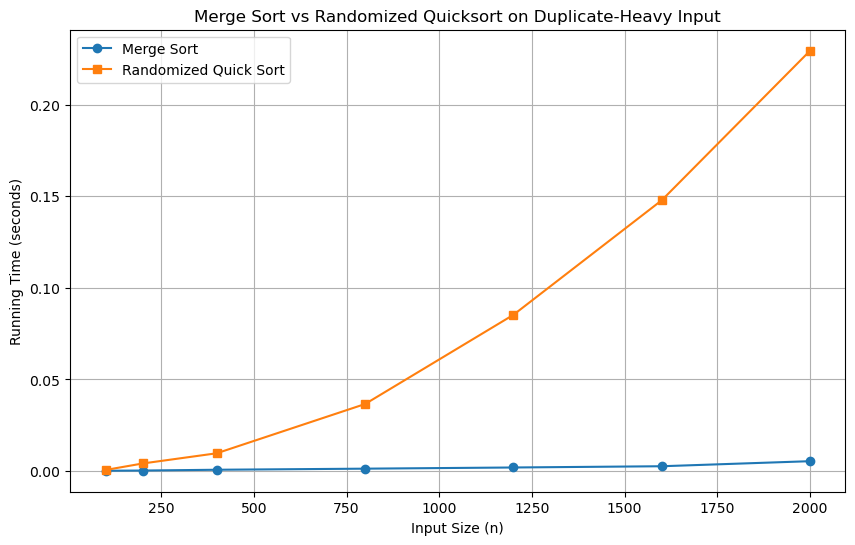

In [1]:
import random
import time
import matplotlib.pyplot as plt


# ============================================================
# MERGE SORT
# ============================================================

def merge(left, right):
    result = []
    i = j = 0

    while i < len(left) and j < len(right):
        if left[i] <= right[j]:
            result.append(left[i])
            i += 1
        else:
            result.append(right[j])
            j += 1

    result.extend(left[i:])
    result.extend(right[j:])

    return result


def merge_sort(arr):
    if len(arr) <= 1:
        return arr[:]

    mid = len(arr) // 2

    left = merge_sort(arr[:mid])
    right = merge_sort(arr[mid:])

    return merge(left, right)


# ============================================================
# RANDOMIZED QUICKSORT
# ============================================================

def partition(arr, p, q):
    x = arr[p]
    i = p

    for j in range(p + 1, q + 1):
        if arr[j] <= x:
            i += 1
            arr[i], arr[j] = arr[j], arr[i]

    arr[p], arr[i] = arr[i], arr[p]

    return i


def randomized_partition(arr, p, q):
    rand_index = random.randint(p, q)

    arr[rand_index], arr[p] = arr[p], arr[rand_index]

    return partition(arr, p, q)


def quicksort(arr, p=0, q=None):
    if q is None:
        q = len(arr) - 1

    if p < q:
        pivot_index = randomized_partition(arr, p, q)

        quicksort(arr, p, pivot_index - 1)
        quicksort(arr, pivot_index + 1, q)

    return arr


# ============================================================
# MEASUREMENT
# ============================================================

def measure_time(sort_function, arr):
    data = arr[:]

    start = time.perf_counter()
    sort_function(data)
    end = time.perf_counter()

    return end - start


# ============================================================
# DUPLICATE-HEAVY INPUT
# ============================================================

sizes = [100, 200, 400, 800, 1200, 1600, 2000]

merge_times = []
quick_times = []

for n in sizes:

    # All elements are equal.
    data = [5] * n

    merge_time = measure_time(merge_sort, data)

    # Several trials because randomized quicksort
    # has a random pivot.
    quick_time = 0

    for _ in range(3):
        quick_time += measure_time(quicksort, data)

    quick_time /= 3

    merge_times.append(merge_time)
    quick_times.append(quick_time)

    print(
        f"n={n}: "
        f"Merge={merge_time:.6f}s, "
        f"Quick={quick_time:.6f}s"
    )


# ============================================================
# GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    sizes,
    merge_times,
    marker="o",
    label="Merge Sort"
)

plt.plot(
    sizes,
    quick_times,
    marker="s",
    label="Randomized Quick Sort"
)

plt.xlabel("Input Size (n)")
plt.ylabel("Running Time (seconds)")
plt.title("Merge Sort vs Randomized Quicksort on Duplicate-Heavy Input")

plt.legend()
plt.grid(True)
plt.show()

## Solution 3

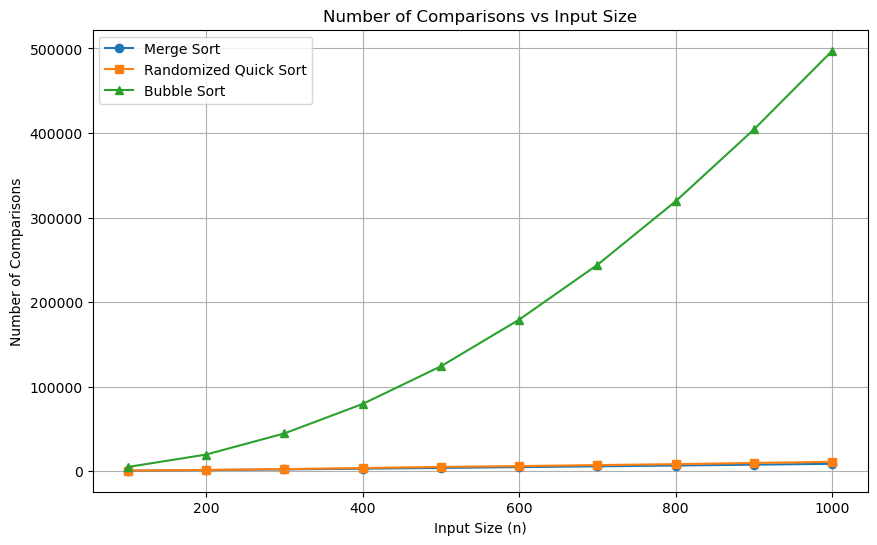

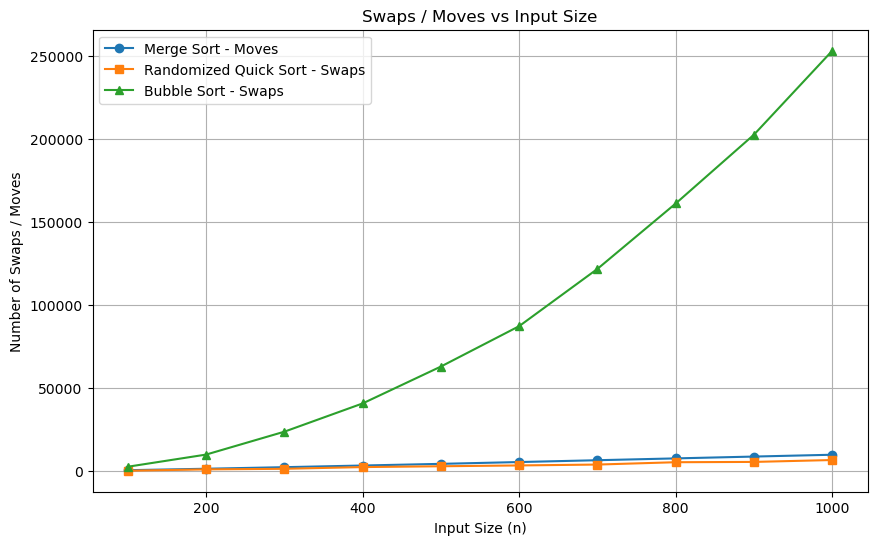

In [2]:
import random
import matplotlib.pyplot as plt


# ============================================================
# MERGE SORT WITH COMPARISON AND MOVE COUNTERS
# ============================================================

def merge_count(left, right, stats):
    result = []

    i = 0
    j = 0

    while i < len(left) and j < len(right):

        # Comparison
        stats["comparisons"] += 1

        if left[i] <= right[j]:
            result.append(left[i])
            stats["moves"] += 1
            i += 1

        else:
            result.append(right[j])
            stats["moves"] += 1
            j += 1

    while i < len(left):
        result.append(left[i])
        stats["moves"] += 1
        i += 1

    while j < len(right):
        result.append(right[j])
        stats["moves"] += 1
        j += 1

    return result


def merge_sort_count(arr, stats=None):

    if stats is None:
        stats = {
            "comparisons": 0,
            "swaps": 0,
            "moves": 0
        }

    if len(arr) <= 1:
        return arr[:], stats

    mid = len(arr) // 2

    left, stats = merge_sort_count(arr[:mid], stats)
    right, stats = merge_sort_count(arr[mid:], stats)

    result = merge_count(left, right, stats)

    return result, stats


# ============================================================
# QUICKSORT WITH COUNTERS
# ============================================================

def partition_count(arr, p, q, stats):

    x = arr[p]
    i = p

    for j in range(p + 1, q + 1):

        # Comparison
        stats["comparisons"] += 1

        if arr[j] <= x:
            i += 1

            arr[i], arr[j] = arr[j], arr[i]

            stats["swaps"] += 1

    # Final pivot swap
    arr[p], arr[i] = arr[i], arr[p]

    stats["swaps"] += 1

    return i


def randomized_partition_count(arr, p, q, stats):

    rand_index = random.randint(p, q)

    # Random-pivot swap
    arr[rand_index], arr[p] = arr[p], arr[rand_index]

    stats["swaps"] += 1

    return partition_count(arr, p, q, stats)


def quicksort_count(arr, p=0, q=None, stats=None):

    if stats is None:
        stats = {
            "comparisons": 0,
            "swaps": 0,
            "moves": 0
        }

    if q is None:
        q = len(arr) - 1

    if p < q:

        pivot_index = randomized_partition_count(
            arr, p, q, stats
        )

        quicksort_count(
            arr,
            p,
            pivot_index - 1,
            stats
        )

        quicksort_count(
            arr,
            pivot_index + 1,
            q,
            stats
        )

    return arr, stats


# ============================================================
# BUBBLE SORT WITH COUNTERS
# ============================================================

def bubble_sort_count(arr):

    arr = arr[:]

    stats = {
        "comparisons": 0,
        "swaps": 0,
        "moves": 0
    }

    n = len(arr)

    for i in range(n):

        swapped = False

        for j in range(0, n - i - 1):

            # Comparison
            stats["comparisons"] += 1

            if arr[j] > arr[j + 1]:

                arr[j], arr[j + 1] = (
                    arr[j + 1],
                    arr[j]
                )

                stats["swaps"] += 1

                swapped = True

        if not swapped:
            break

    return arr, stats


# ============================================================
# EXPERIMENT
# ============================================================

sizes = list(range(100, 1001, 100))

merge_comparisons = []
quick_comparisons = []
bubble_comparisons = []

merge_moves = []
quick_swaps = []
bubble_swaps = []


for n in sizes:

    data = [
        random.randint(0, 100000)
        for _ in range(n)
    ]

    # Merge Sort
    _, merge_stats = merge_sort_count(data)

    # Randomized Quicksort
    _, quick_stats = quicksort_count(data[:])

    # Bubble Sort
    _, bubble_stats = bubble_sort_count(data)

    merge_comparisons.append(
        merge_stats["comparisons"]
    )

    quick_comparisons.append(
        quick_stats["comparisons"]
    )

    bubble_comparisons.append(
        bubble_stats["comparisons"]
    )

    merge_moves.append(
        merge_stats["moves"]
    )

    quick_swaps.append(
        quick_stats["swaps"]
    )

    bubble_swaps.append(
        bubble_stats["swaps"]
    )


# ============================================================
# COMPARISONS GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    sizes,
    merge_comparisons,
    marker="o",
    label="Merge Sort"
)

plt.plot(
    sizes,
    quick_comparisons,
    marker="s",
    label="Randomized Quick Sort"
)

plt.plot(
    sizes,
    bubble_comparisons,
    marker="^",
    label="Bubble Sort"
)

plt.xlabel("Input Size (n)")
plt.ylabel("Number of Comparisons")

plt.title("Number of Comparisons vs Input Size")

plt.legend()
plt.grid(True)
plt.show()


# ============================================================
# SWAPS / MOVES GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    sizes,
    merge_moves,
    marker="o",
    label="Merge Sort - Moves"
)

plt.plot(
    sizes,
    quick_swaps,
    marker="s",
    label="Randomized Quick Sort - Swaps"
)

plt.plot(
    sizes,
    bubble_swaps,
    marker="^",
    label="Bubble Sort - Swaps"
)

plt.xlabel("Input Size (n)")
plt.ylabel("Number of Swaps / Moves")

plt.title("Swaps / Moves vs Input Size")

plt.legend()
plt.grid(True)
plt.show()

## Solution 4

1. Bubble Sort: Small input ; Simplicity more important than performance ; Learning or demonstrating sorting algos

2. Merge Sort: Need guaranteed O(nlogn) ; worst-case performance matters ; need stable sort ; additional memory is fine

3. Randomized Quick Sort: Very good average performance ; In place sorting ; Low memory usage

4. Mergesort then quicksort: Less common. Can be possibly used when Mergesort is used to produce large sorted runs then Quicksort on selected partitions where in place processing is advantageous.

5. Quicksort then Mergesort: Useful as quicksort can be used to partition data into useful groups and mergesort is applied where stability and guaranteed performance is desired.